# Medical Insurance Cost Estimator

In [65]:
# Imports
import pandas as pd
import numpy as np

# Graphing
import seaborn as sns
import matplotlib.pyplot as plt

# Machine Learning Model
import sklearn
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [49]:
# Visualize Graphs
%matplotlib inline

In [50]:
# Read CSV 
df = pd.read_csv("data/insurance.csv")

## Exploratory Analysis

In [51]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [52]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [53]:
# Transform 
df['smoker'] = df['smoker'].map({'yes':1, 'no':0})

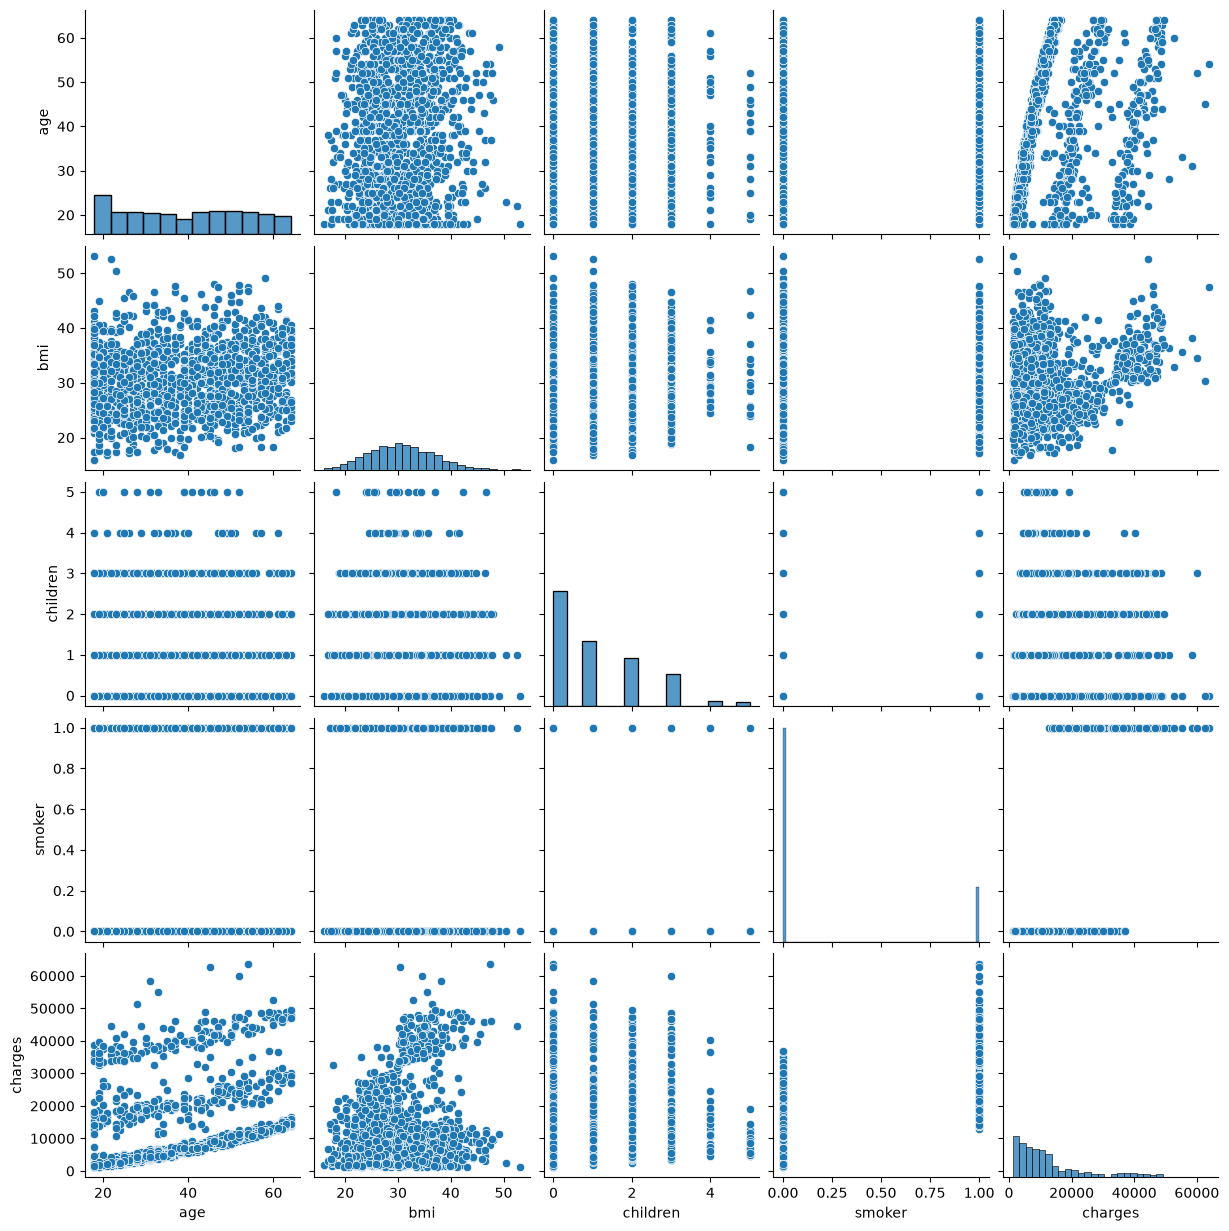

In [54]:
sns.pairplot(df)

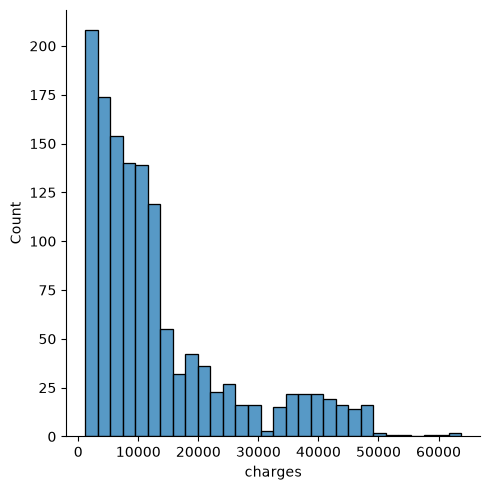

In [55]:
# Target is Charges
sns.displot(df['charges'])

<Axes: >

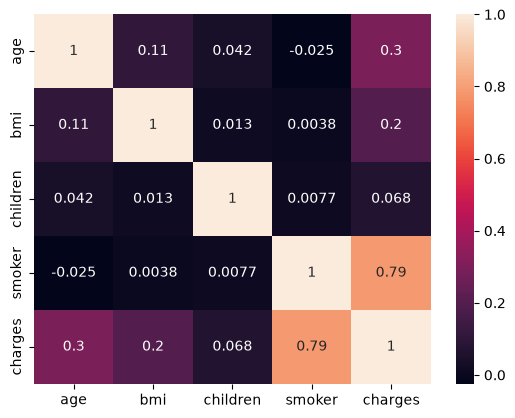

In [56]:
# See Correllations
sns.heatmap(df[['age', 'bmi', 'children', 'smoker', 'charges']].corr(),
            annot=True)

### Findings:
People who are smokers tend to have higher charges.
<br>**Reason**: Higher chances of lung cancer and lung infections & diseases
<br>
<br>
Older people tend to have higher charges
<br>**Reason**: Older people are more suseptable to illnesses and need long term cronic care
<br>
<br>
People with high BMI's tend to have higher charges.
<br>**Reason**: Higher BMI's resonate with having internal causes. Such as diabetes, obesity, and often hormone imbalances.

## Train Model
### Linear Regression

In [57]:
# Format Data
X = df[['age', 'bmi', 'children', 'smoker']]
y = df['charges']

In [58]:
# Split Data
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.3,
                                                    random_state=32)

In [59]:
# Initiate Model
linModel = sklearn.linear_model.LinearRegression()

In [60]:
# Train Model on Training Data
linModel.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 256.37, 342.51, 495.98,23562.78]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['age','bmi','children','smoker']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.263e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [61]:
# Understand Coeffs
pd.DataFrame(linModel.coef_, X.columns, columns=['Coeff'])

,Coeff
age,256.367617
bmi,342.511005
children,495.980368
smoker,23562.784071


## Make Predictions

In [62]:
predictions = linModel.predict(X_test)

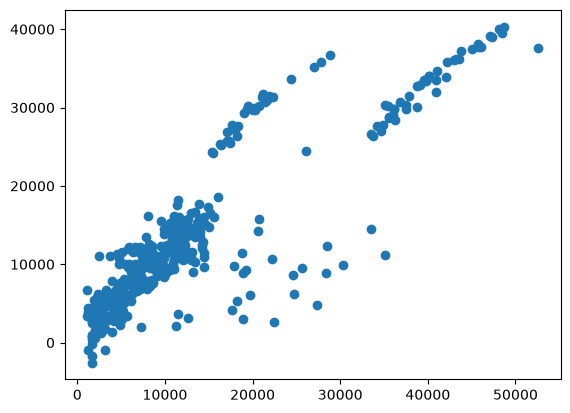

In [ ]:
plt.scatter(y_test, predictions)

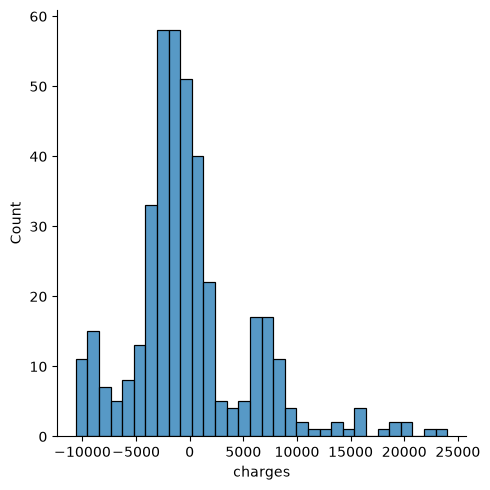

In [67]:
# Plot Residuals
sns.displot((y_test-predictions))

# If Noramlly distributed: Linear Regression is right choice
#   Else: Try different Model

In [68]:
# Show Evaluation Metrics
print('MAE:\t', metrics.mean_absolute_error(y_test, predictions))
print('MSE:\t', metrics.mean_squared_error(y_test, predictions))
print('RMSE:\t', metrics.root_mean_squared_error(y_test, predictions))

MAE:	 3921.3308588417412
MSE:	 31249003.59729316
RMSE:	 5590.080822071642


In [70]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, predictions)

print(f"R²: {r2:.4f}")

R²: 0.7724


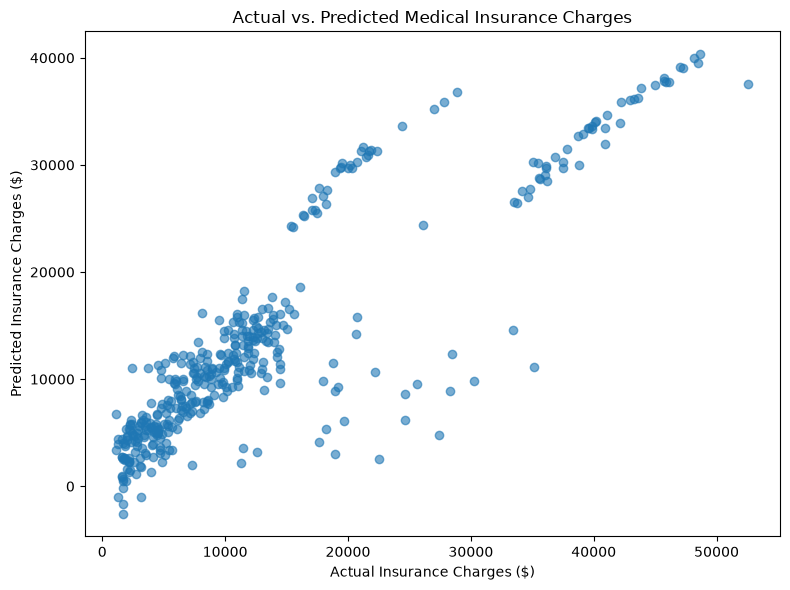

In [71]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.6)

plt.xlabel("Actual Insurance Charges ($)")
plt.ylabel("Predicted Insurance Charges ($)")
plt.title("Actual vs. Predicted Medical Insurance Charges")

plt.tight_layout()
plt.show()